# 街道环境质量代理：基线预测

空间网格分组训练/验证/测试；目标与特征标准化仅在训练集拟合。

# 环境质量代理目标：基线模型结果

已完成均值预测、线性回归、随机森林、梯度提升基线。视觉代理目标304条道路为主分析；完整代理目标46条仅作小样本补充。目标是既定环境代理公式，不是独立环境质量真值。

## 数据划分与防泄漏

以道路记录为样本，304条道路的OSM编号不重复。按经纬度0.005度网格（约500米量级）成组划分，网格不跨训练、验证、测试集，约60%/20%/20%，随机种子43。共同划分先固定，再取完整目标子样本。种子仅按预设样本数量下限选择，未依据目标得分或模型表现选择。没有空间缓冲带，相邻网格的道路仍可能相近，不能宣称完全空间独立；不等同于跨城市泛化。

全部特征缺值填补、数值缩放及类别编码仅在训练集拟合，未知类别忽略。绿化、车辆、限速及其标准分、综合分数、计数覆盖与质量标记不进入自变量。road_only使用道路等级、结构类型、单向属性和layer；road_context另加建筑、天空、人物背景特征。这些视觉背景与标签来自同批图像，可能共享识别误差，解释为同源背景信息的预测关联。

**目标标准化也仅在对应任务训练集拟合**：对训练道路原指标拟合5%/95%分位数，再应用于验证、测试道路。因此`训练尺度目标值.csv`与此前全样本标准化的v1指数可能不同，不能混用评价指标或分组。原v1数据表不改写。低可见车辆取log(1+x)，正负方向和等权公式沿用既定规则。

随机森林比较min_samples_leaf=3/8；梯度提升比较深度1/2；线性回归和均值预测无调参。先按验证集MAE为各模型选择参数，再按验证集MAE选定模型与特征集，包含均值预测参照。所有模型仍只拟合训练集，测试集不用于选择或重新调参。测试分数为一次固定划分结果，无多次交叉验证置信区间。

## 验证集选定模型

- visual_proxy：{'train': 176, 'test': 73, 'validation': 55}；road_context / linear；测试 MAE=10.563，RMSE=13.933，R²=0.454。
- complete_proxy：{'train': 26, 'validation': 13, 'test': 7}；road_context / linear；测试 MAE=12.981，RMSE=14.526，R²=0.448。

## 各基线的测试集表现

| task | feature_set | model | n | MAE | RMSE | R2 |
| --- | --- | --- | --- | --- | --- | --- |
| visual_proxy | road_only | mean | 73 | 14.785 | 18.906 | -0.006 |
| visual_proxy | road_only | linear | 73 | 13.502 | 17.195 | 0.168 |
| visual_proxy | road_only | random_forest | 73 | 13.326 | 17.093 | 0.178 |
| visual_proxy | road_only | gradient_boosting | 73 | 13.564 | 17.219 | 0.166 |
| visual_proxy | road_context | mean | 73 | 14.785 | 18.906 | -0.006 |
| visual_proxy | road_context | linear | 73 | 10.563 | 13.933 | 0.454 |
| visual_proxy | road_context | random_forest | 73 | 12.291 | 15.308 | 0.341 |
| visual_proxy | road_context | gradient_boosting | 73 | 13.072 | 16.219 | 0.26 |
| complete_proxy | road_only | mean | 7 | 20.974 | 23.542 | -0.451 |
| complete_proxy | road_only | linear | 7 | 15.19 | 17.315 | 0.215 |
| complete_proxy | road_only | random_forest | 7 | 15.987 | 18.413 | 0.113 |
| complete_proxy | road_only | gradient_boosting | 7 | 16.067 | 18.304 | 0.123 |
| complete_proxy | road_context | mean | 7 | 20.974 | 23.542 | -0.451 |
| complete_proxy | road_context | linear | 7 | 12.981 | 14.526 | 0.448 |
| complete_proxy | road_context | random_forest | 7 | 12.829 | 14.781 | 0.428 |
| complete_proxy | road_context | gradient_boosting | 7 | 10.371 | 11.264 | 0.668 |

MAE、RMSE越小越好；R²可能为负，表示相对测试样本均值的平方误差参照较差。均值模型实际预测的是训练集均值。报告所有基线测试分数用于比较，不以测试最佳重新选定模型。预测值不截断，以免隐藏误差。完整目标测试集很小，不据此确定模型优劣或宣称已达到应用精度。

结果只针对有合格图像和属性的道路；目标仍是研究者设定的环境质量代理，不能作为独立环境效度验证。后续需要更多标注、独立环境评价和空间重复划分核查。

方法实现参考 [scikit-learn 数据泄漏与 Pipeline 说明](https://scikit-learn.org/1.5/common_pitfalls.html)；该文档支持训练集拟合预处理的流程，不为本项目代理目标提供效度背书。

## 初步结论

主分析验证集选定模型为 road_context / linear，测试MAE为10.563，训练均值预测MAE为14.785，误差相对变化为-28.6%。模型对既定代理目标提供的预测能力不等于对独立环境质量的验证。完整目标测试集仅7条道路，验证与测试误差差异明显，应等待更多样本再解释稳定性。


,task,feature_set,model,parameters,split,fit_sec,MAE,RMSE,R2,n
0,visual_proxy,road_only,mean,{},train,0.009326,18.310619,22.640026,0.000000,176
1,visual_proxy,road_only,mean,{},validation,0.009326,14.781540,17.827554,-0.041364,55
2,visual_proxy,road_only,mean,{},test,0.009326,14.785200,18.906477,-0.005579,73
3,visual_proxy,road_only,linear,{},train,0.030333,17.772097,21.898569,0.064427,176
4,visual_proxy,road_only,linear,{},validation,0.030333,11.453623,14.333543,0.326828,55
5,visual_proxy,road_only,linear,{},test,0.030333,13.501770,17.194946,0.168243,73
6,visual_proxy,road_only,random_forest,"{""min_samples_leaf"": 3}",train,0.245998,17.255626,21.106740,0.130863,176
7,visual_proxy,road_only,random_forest,"{""min_samples_leaf"": 3}",validation,0.245998,12.901003,15.521514,0.210618,55
8,visual_proxy,road_only,random_forest,"{""min_samples_leaf"": 3}",test,0.245998,13.325540,17.093149,0.178062,73
9,visual_proxy,road_only,gradient_boosting,"{""max_depth"": 1}",train,0.030065,17.857837,21.912891,0.063203,176


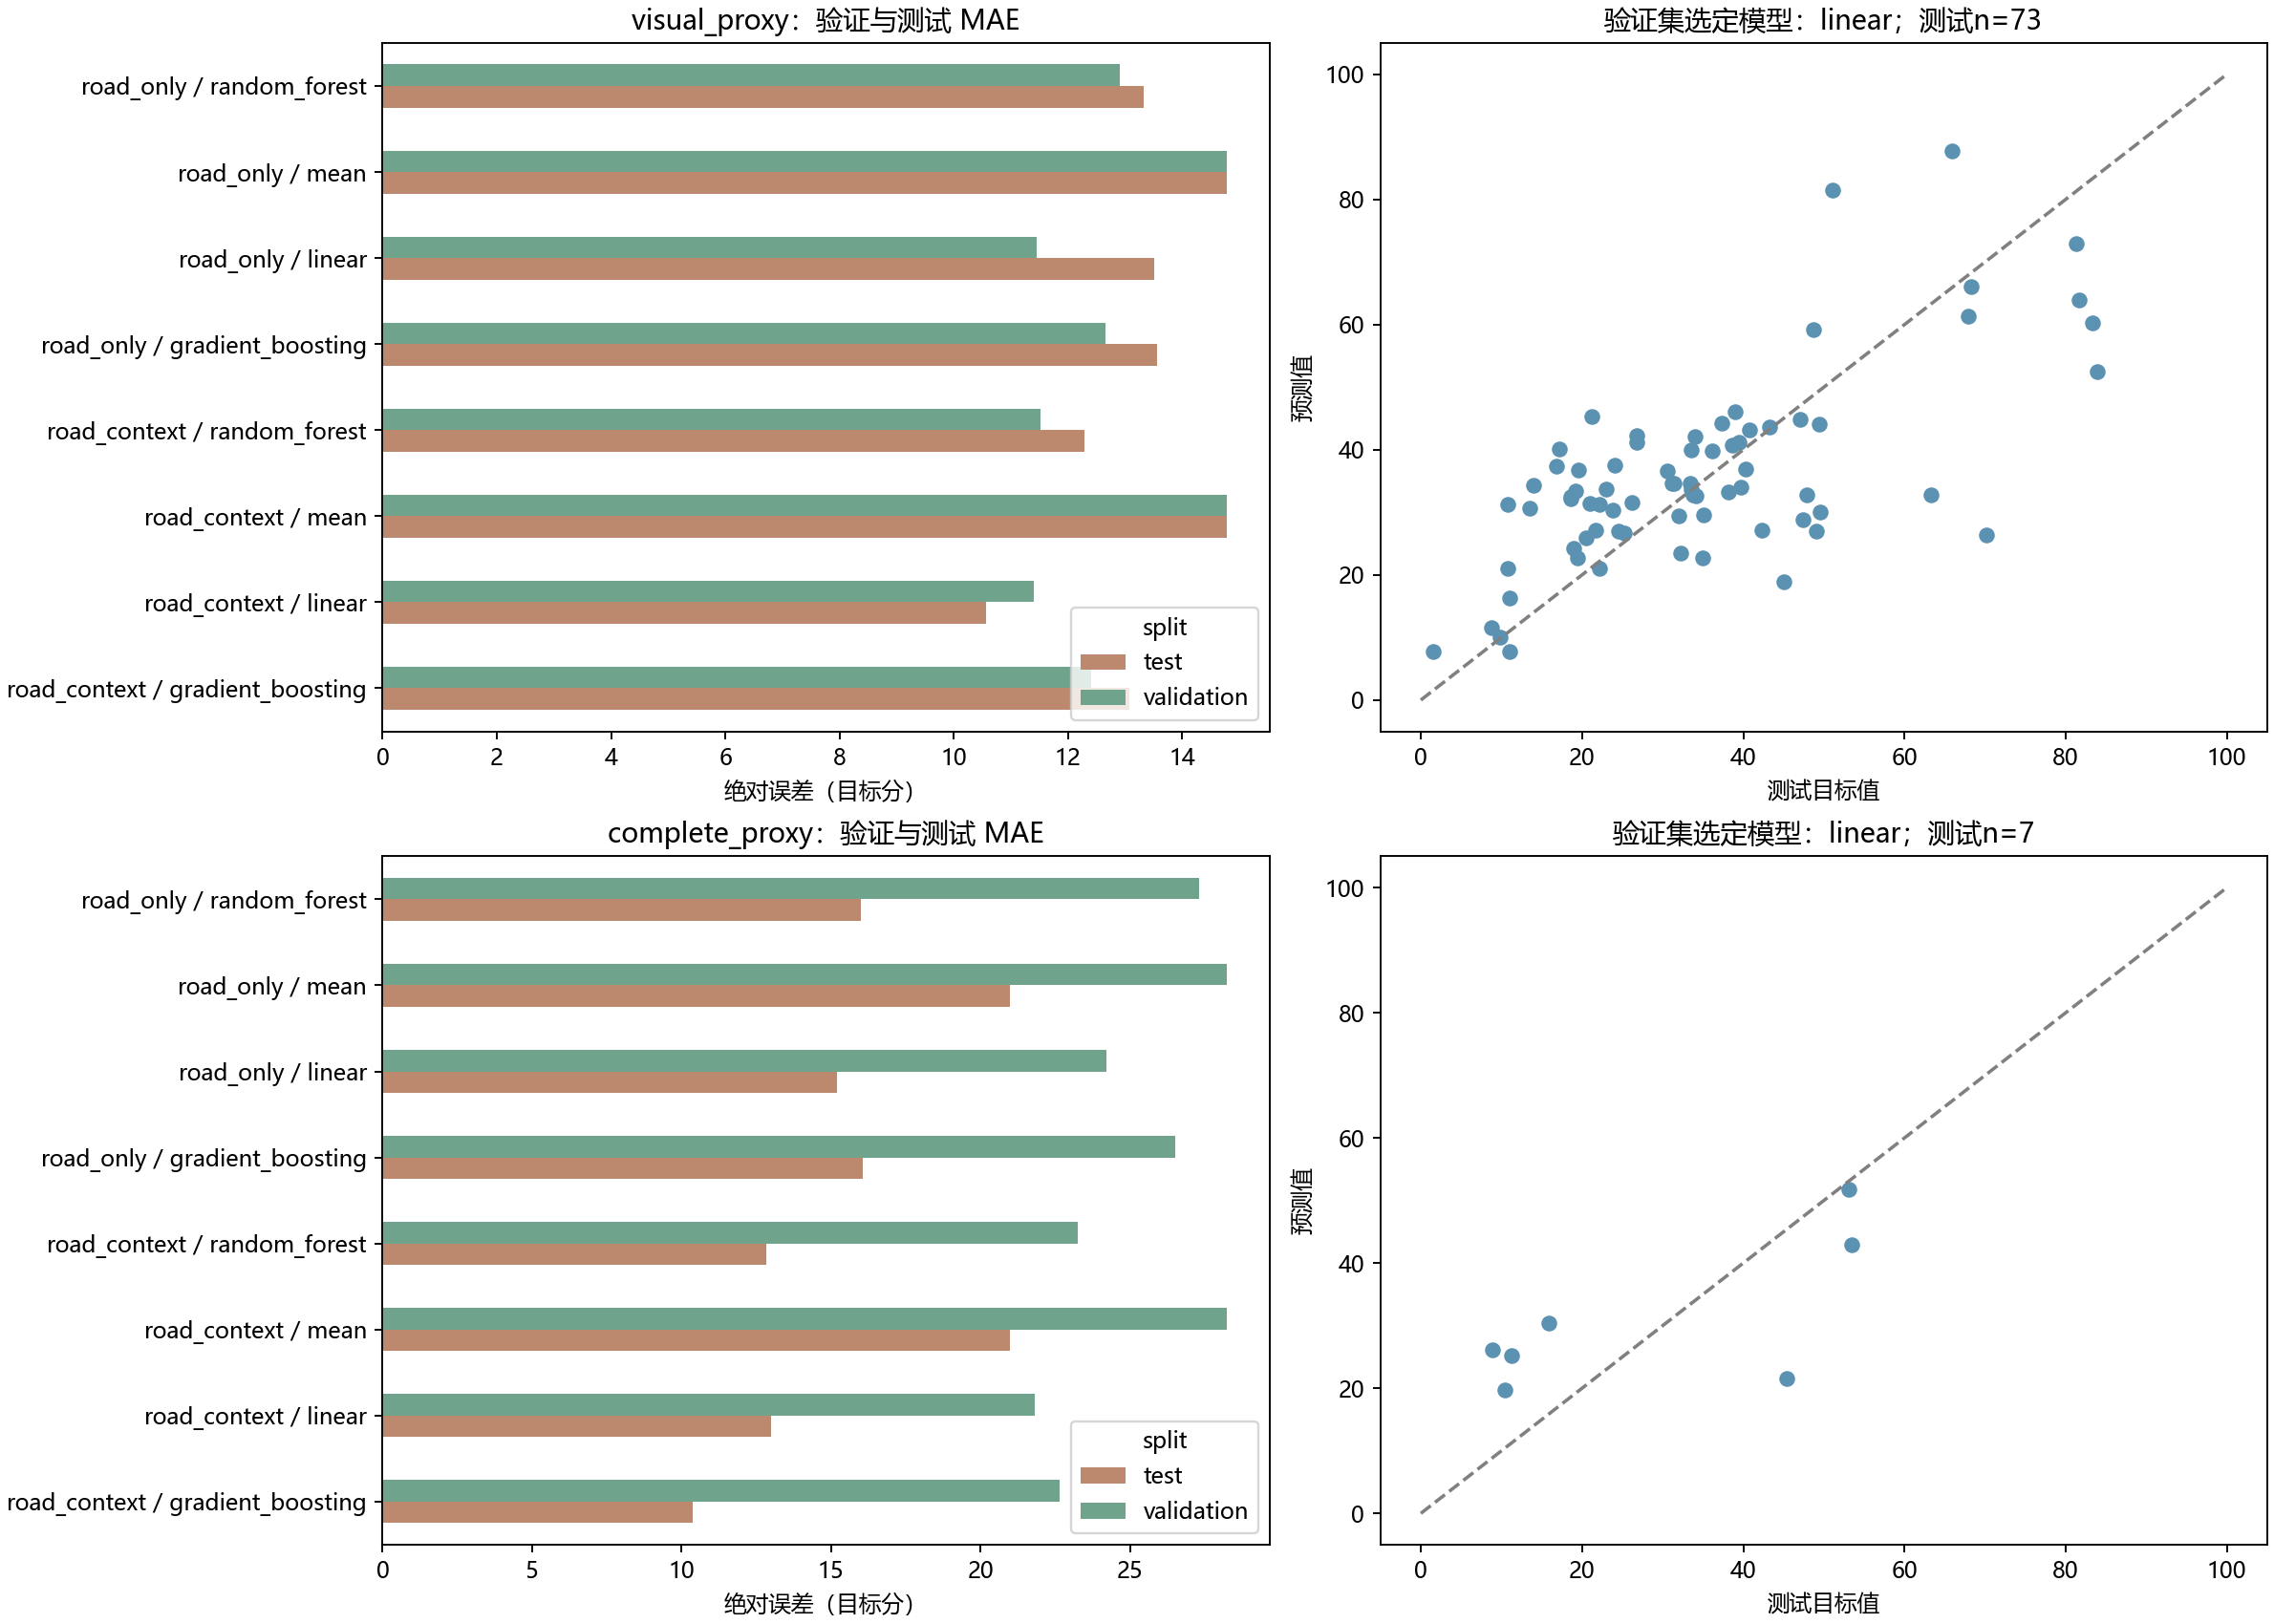

In [1]:
from pathlib import Path
import subprocess,sys
import pandas as pd
from IPython.display import display,Image,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/train_environment_baselines.py').exists())
subprocess.run([sys.executable,str(ROOT/'scripts/train_environment_baselines.py')],cwd=ROOT,check=True)
OUT=ROOT/'outputs/environment_baselines_v1'
display(Markdown((OUT/'基线模型结果与评价说明.md').read_text(encoding='utf-8')))
display(pd.read_csv(OUT/'基线模型评价指标.csv',encoding='utf-8-sig'))
display(Image(filename=str(OUT/'基线模型评价与预测.png')))
